# 05 - Customer segmentation (unsupervised learning)

No labels: discover customer groups from behaviour. Covers K-Means (with K-Means++ and the elbow / silhouette methods), hierarchical clustering with a dendrogram, DBSCAN for odd shapes and outliers, and Gaussian mixtures for *soft* assignments.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
import mlforge
from mlforge import visualization as viz
print("MLForge", mlforge.__version__)

MLForge 0.2.0


## Synthetic customers with four hidden personas

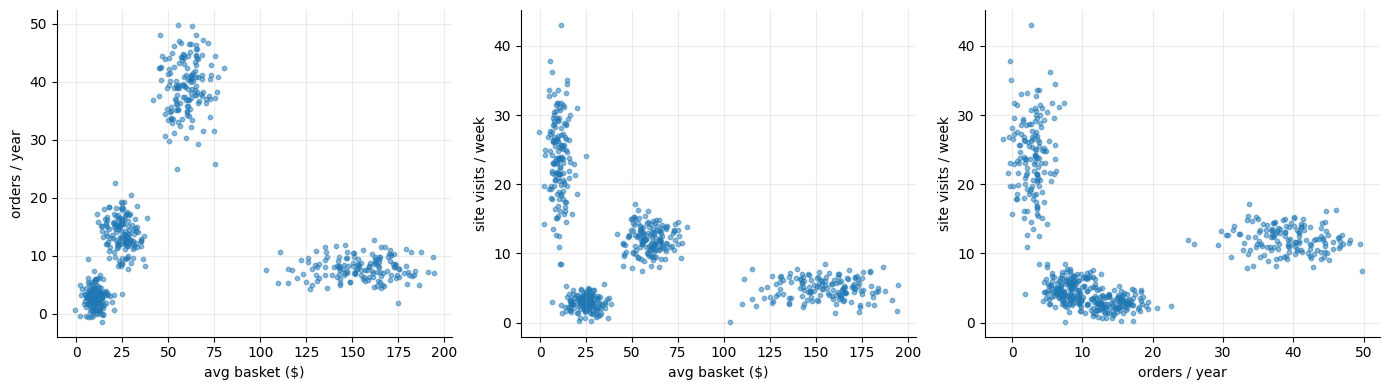

In [2]:
rng = np.random.RandomState(7)
personas = {"Bargain hunters": ([25, 14, 3], [6, 3, 1]), "Loyal regulars": ([60, 40, 12], [8, 5, 2]),
            "Big spenders":  ([150, 8, 5], [20, 2, 1.5]), "Window shoppers": ([10, 3, 25], [4, 1.5, 6])}
X, truth = [], []
for k, (mu, sd) in enumerate(personas.values()):
    X.append(rng.randn(150, 3) * sd + mu); truth += [k] * 150
X, truth = np.vstack(X), np.array(truth)
cols = ["avg basket ($)", "orders / year", "site visits / week"]
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (i, j) in zip(ax, [(0, 1), (0, 2), (1, 2)]): a.scatter(X[:, i], X[:, j], s=10, alpha=.5); a.set_xlabel(cols[i]); a.set_ylabel(cols[j])
plt.tight_layout()

## Scale first, then choose k
Distance-based clustering needs standardised features. The **elbow** (inertia) and the **silhouette** both help pick k.

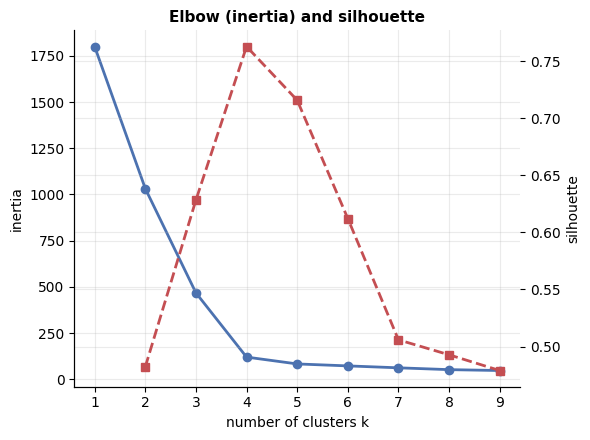

In [3]:
from mlforge.preprocessing import StandardScaler
from mlforge.cluster import KMeans, elbow_curve, silhouette_curve
Z = StandardScaler().fit_transform(X)
ks = list(range(1, 10))
viz.plot_elbow(ks, elbow_curve(Z, ks), silhouette_curve(Z, range(2, 10)), title="Elbow (inertia) and silhouette");

silhouette: 0.763  Davies-Bouldin: 0.293  ARI vs hidden personas: 0.982


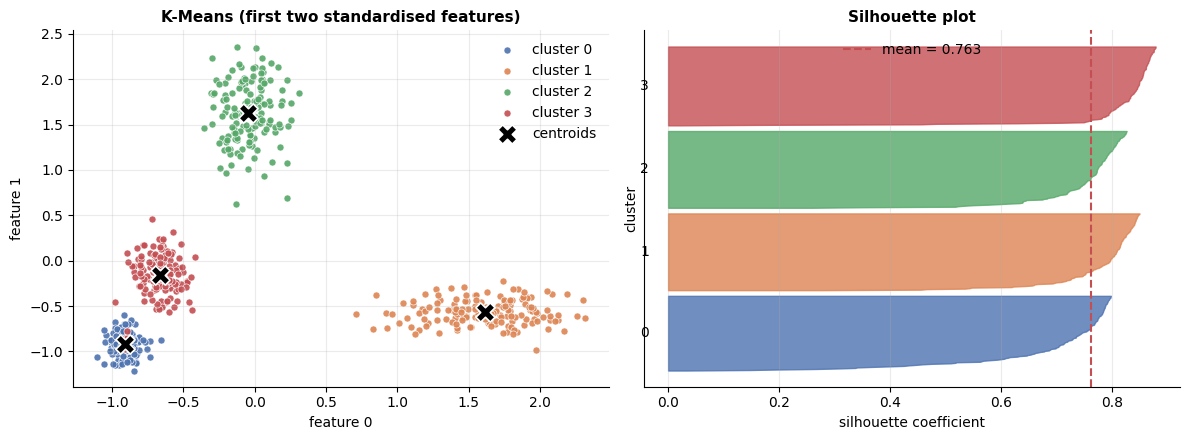

In [4]:
km = KMeans(4, n_init=10, random_state=0).fit(Z)
from mlforge.metrics import silhouette_score, adjusted_rand_score, davies_bouldin_score
print("silhouette:", round(silhouette_score(Z, km.labels_), 3), " Davies-Bouldin:", round(davies_bouldin_score(Z, km.labels_), 3),
      " ARI vs hidden personas:", round(adjusted_rand_score(truth, km.labels_), 3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
viz.plot_clusters(Z[:, :2], km.labels_, km.cluster_centers_[:, :2], ax=ax[0], title="K-Means (first two standardised features)")
viz.plot_silhouette(Z, km.labels_, ax=ax[1]); plt.tight_layout()

## Profile the segments
Turn cluster centres back into business units.

In [5]:
sc = StandardScaler().fit(X)
centres = sc.inverse_transform(km.cluster_centers_)
sizes = np.bincount(km.labels_)
print(f"{'cluster':>8}{'size':>6}" + "".join(f"{c:>20}" for c in cols))
for k in np.argsort(centres[:, 0]): print(f"{k:>8}{sizes[k]:>6}" + "".join(f"{v:>20.1f}" for v in centres[k]))

 cluster  size      avg basket ($)       orders / year  site visits / week
       0   146                10.2                 2.8                24.4
       3   154                24.4                13.7                 3.1
       2   150                59.8                39.3                12.0
       1   150               154.5                 7.9                 4.9


## Watch K-Means converge

In [6]:
print("iterations to converge:", km.n_iter_, "| inertia:", round(km.inertia_, 1))
km1 = KMeans(4, init="random", n_init=1, random_state=3).fit(Z[:, :2])
print("single random start inertia:", round(km1.inertia_, 1), "-> best of 10 K-Means++ starts:", round(KMeans(4, n_init=10, random_state=0).fit(Z[:, :2]).inertia_, 1))
# viz.animate_kmeans(km1, Z[:, :2], 'kmeans.gif')   # writes an animated GIF of the centroid trajectory

iterations to converge: 4 | inertia: 120.7
single random start inertia: 86.7 -> best of 10 K-Means++ starts: 47.2


## Hierarchical clustering and the dendrogram

single    ARI vs personas = 0.713


complete  ARI vs personas = 0.791
average   ARI vs personas = 0.991
ward      ARI vs personas = 1.000


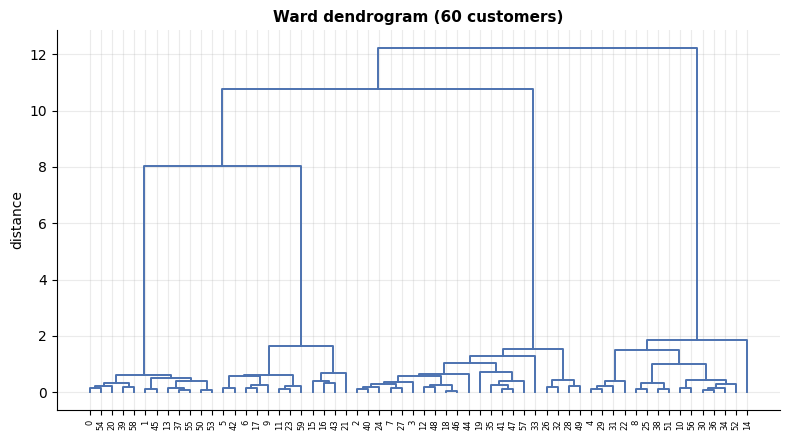

In [7]:
from mlforge.cluster import linkage, fcluster, AgglomerativeClustering
idx = rng.choice(len(Z), 60, replace=False)
Zl = linkage(Z[idx], "ward")
viz.plot_dendrogram(Zl, title="Ward dendrogram (60 customers)")
for m in ["single", "complete", "average", "ward"]:
    lab = AgglomerativeClustering(4, m).fit(Z).labels_
    print(f"{m:<9} ARI vs personas = {adjusted_rand_score(truth, lab):.3f}")

## DBSCAN: arbitrary shapes and outliers
K-Means assumes round clusters. On two interleaved moons it fails; DBSCAN succeeds and flags noise.

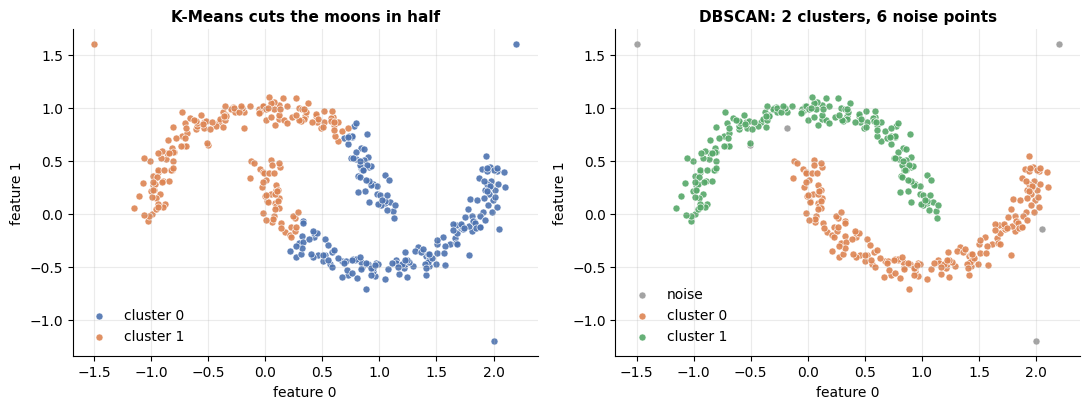

In [8]:
from mlforge.datasets import make_moons
from mlforge.cluster import DBSCAN
M, mt = make_moons(400, 0.07, random_state=0); M = np.vstack([M, [[2.2, 1.6], [-1.5, 1.6], [2, -1.2]]])   # plus 3 outliers
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
viz.plot_clusters(M, KMeans(2, random_state=0).fit(M).labels_, ax=ax[0], title="K-Means cuts the moons in half")
db = DBSCAN(0.15, 5).fit(M); viz.plot_clusters(M, db.labels_, ax=ax[1], title=f"DBSCAN: {db.n_clusters_} clusters, {(db.labels_ == -1).sum()} noise points"); plt.tight_layout()

## Gaussian mixtures: soft assignments and model selection by BIC

In [9]:
from mlforge.cluster import GaussianMixture
bics = [GaussianMixture(k, random_state=0).fit(Z).bic(Z) for k in range(1, 8)]
print("BIC by k:", np.round(bics, 0), "-> best k =", 1 + int(np.argmin(bics)))
gmm = GaussianMixture(4, random_state=0).fit(Z)
resp = gmm.predict_proba(Z)
conf = resp.max(1)
print("assignment confidence (max responsibility) - 1st / 5th percentile / median:", np.round(np.quantile(conf, [0.01, 0.05, 0.5]), 4))
print("least certain customer:", int(conf.argmin()), "->", np.round(resp[conf.argmin()], 3), "(a soft assignment, unlike K-Means)")
print("EM log-likelihood increased monotonically:", bool(np.all(np.diff(gmm.log_likelihood_history_) > -1e-9)))
print("ARI vs personas:", round(adjusted_rand_score(truth, gmm.predict(Z)), 3))

BIC by k: [5001. 2822. 1385.  744.  793.  843.  892.] -> best k = 4
assignment confidence (max responsibility) - 1st / 5th percentile / median: [1. 1. 1.]
least certain customer: 128 -> [0. 0. 0. 1.] (a soft assignment, unlike K-Means)
EM log-likelihood increased monotonically: True
ARI vs personas: 1.0
